In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
file='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/SMAP_03-07_0.1x0.1gridded_cropfiltered.parquet'
smap=pd.read_parquet(file, engine='pyarrow')


In [3]:
smap = smap.copy()
smap['datetime'] = pd.to_datetime(smap['datetime'])

smap = smap.sort_values(['grid_lat','grid_lon','datetime'])
smap = smap.set_index(['grid_lat','grid_lon','datetime'])

# recompute numeric columns on the indexed frame
num_cols = [c for c in smap.columns if pd.api.types.is_numeric_dtype(smap[c])]

tmin = smap.index.get_level_values('datetime').min().floor('h')
tmax = smap.index.get_level_values('datetime').max().ceil('h')
tempo_hours = pd.date_range(tmin, tmax, freq='1h')

def upsample_interp(g):
    g = g.droplevel(['grid_lat','grid_lon']).sort_index()
    g_num = g[num_cols]

    union_idx = g_num.index.union(tempo_hours)
    g_num_u = (g_num.reindex(union_idx)
                     .interpolate(method='time', limit_area='inside'))
    g_num_hr = g_num_u.reindex(tempo_hours)
    return g_num_hr

smap_hourly = (smap.groupby(level=['grid_lat','grid_lon'], group_keys=True)
                    .apply(upsample_interp)
                    .rename_axis(['grid_lat','grid_lon','datetime'])
                    .reset_index())

In [4]:
smap_hourly

,grid_lat,grid_lon,datetime,sm_surface,surface_temp,soil_temp_layer1,LAI,catchment_model_porosity,WFPS_c
0,36.05,-102.75,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN
1,36.05,-102.75,2024-02-29 23:00:00,0.113800,206.544754,204.246826,0.217461,0.303329,0.272184
2,36.05,-102.75,2024-03-01 00:00:00,0.113779,205.071732,204.240280,0.217711,0.303329,0.272134
3,36.05,-102.75,2024-03-01 01:00:00,0.113758,203.598724,204.233734,0.217961,0.303329,0.272084
4,36.05,-102.75,2024-03-01 02:00:00,0.113927,202.462418,203.997009,0.218211,0.303329,0.272486
...,...,...,...,...,...,...,...,...,...
34454767,48.95,-96.85,2024-07-31 19:00:00,0.072760,303.053467,298.235016,2.061263,0.400238,0.180363
34454768,48.95,-96.85,2024-07-31 20:00:00,0.072827,303.288666,298.772583,2.060860,0.400238,0.180547
34454769,48.95,-96.85,2024-07-31 21:00:00,0.072936,302.871277,299.129700,2.060457,0.400238,0.180834
34454770,48.95,-96.85,2024-07-31 22:00:00,0.073044,302.453888,299.486816,2.060053,0.400238,0.181121


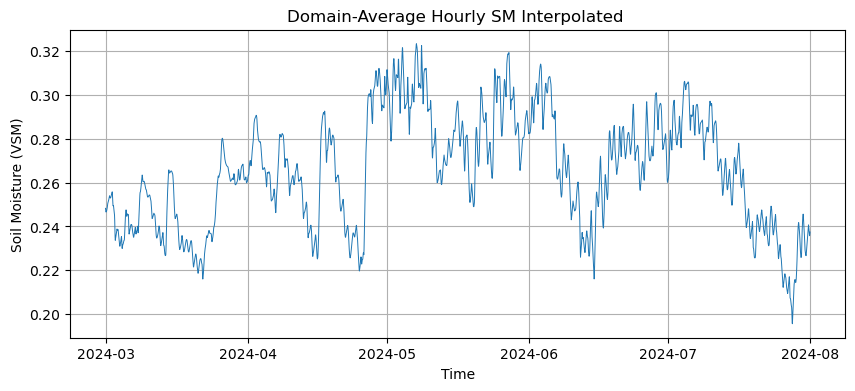

In [5]:
#take avg of grid cells 
mean_hourly_smap = (smap_hourly.groupby('datetime')['sm_surface'].mean().reset_index())

plt.figure(figsize=(10,4))
plt.plot(mean_hourly_smap['datetime'], mean_hourly_smap['sm_surface'], lw=0.7)
plt.title('Domain-Average Hourly SM Interpolated ')
plt.xlabel('Time')
plt.ylabel('Soil Moisture (VSM)')
plt.grid(True)
plt.show()

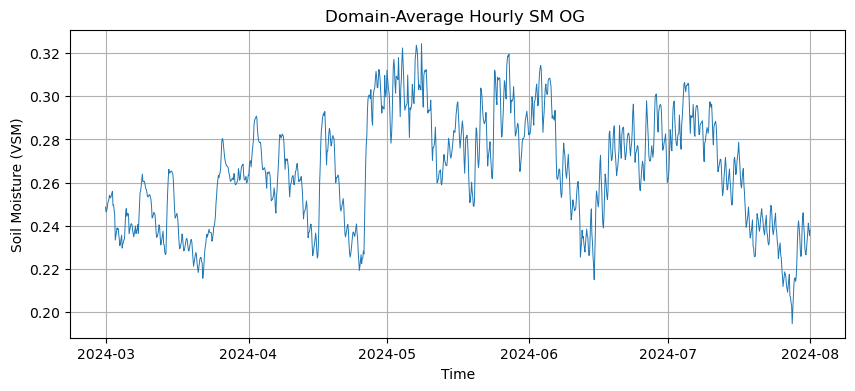

In [6]:
#take avg of grid cells 
mean_smap = (smap.groupby('datetime')['sm_surface'].mean().reset_index())

plt.figure(figsize=(10,4))
plt.plot(mean_smap['datetime'], mean_smap['sm_surface'], lw=0.7)
plt.title('Domain-Average Hourly SM OG ')
plt.xlabel('Time')
plt.ylabel('Soil Moisture (VSM)')
plt.grid(True)
plt.show()

In [9]:
output_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/hourly_SMAP_03-07_0.1x0.1GCF.parquet'
smap_hourly.to_parquet(output_file, engine='pyarrow')